# Example-24: Hurst exponent

In [1]:
from pathlib import Path
import sys

import jax
import jax.numpy as jnp
import numpy as np

jax.config.update("jax_enable_x64", True)
jax.config.update("jax_default_device", jax.devices("cpu")[0])

from tohubohu import cosine, fft, hurst, hexp, nest_list
from tohubohu.fft import fft_entropy
from tohubohu.util import forward4D

from matplotlib import pyplot as plt, colormaps
from matplotlib.colors import Normalize
from matplotlib.ticker import MaxNLocator

cmap = colormaps.get_cmap('turbo').copy()
cmap.set_bad(color='lightgray')

In [2]:
LENGTHS = (64, 128, 256, 512, 1024)

def observable(orbit):
    qx, qy, px, py = orbit.T
    mqx = jax.numpy.mean(qx)
    mpx = jax.numpy.mean(px)
    mqy = jax.numpy.mean(qy)
    mpy = jax.numpy.mean(py)
    sqx = jax.numpy.std(qx)
    spx = jax.numpy.std(px)
    sqy = jax.numpy.std(qy)
    spy = jax.numpy.std(py)
    return 0.5*(((qx - mqx)/sqx)**2 + ((px - mpx)/spx)**2) + 0.5*(((qy - mqy)/sqy)**2 + ((py - mpy)/spy)**2)


def parameters():
    mux, muy = 2*jnp.pi*0.168, 2*jnp.pi*0.201
    return jnp.array([jnp.cos(mux), jnp.sin(mux), jnp.cos(muy), jnp.sin(muy), 0.0])

In [3]:
n = 1001
length = 1024

x = jnp.array([0.2, 0.1, 1e-12, 1e-12])
k = parameters()

In [4]:
# For each segment length, split the series into complete nonoverlapping segments, subtract each segment's mean and form cumulative deviations
# Divide their range R by the segment population standard deviation S and average R/S over segments, fit log <R/S> = _ + H log s

In [5]:
sequence = observable(nest_list(length, forward4D)(x, k))

h_direct = jax.jit(hexp)(sequence)
h_factory = jax.jit(hurst(length, forward4D, observable))(x, k)

print(f"Hurst (direct)  : {float(h_direct):.6f}")
print(f"Hurst (factory) : {float(h_factory):.6f}")

Hurst (direct)  : 0.475703
Hurst (factory) : 0.475703


In [6]:
def compute(n=1024, lengths=LENGTHS, *, include_hurst=True, batch_size=256, radius=5.0):
    lengths = tuple(lengths)
    axis = np.linspace(0.0, 0.6, n)
    qx, qy = np.meshgrid(axis, axis, indexing='xy')
    xs = np.stack([qx.ravel(), qy.ravel(), np.full(n*n, 1e-12), np.full(n*n, 1e-12)], axis=1)
    k = parameters()
    weights = tuple(cosine(t) for t in lengths)
    def measure(x):
        def step(carry, _):
            state, alive = carry
            trial = forward4D(jnp.where(alive, state, jnp.zeros_like(state)), k)
            alive = alive & jnp.all(jnp.isfinite(trial)) & (jnp.sum(trial**2) <= radius**2)
            state = jnp.where(alive, trial, state)
            return (state, alive), state
        (_, survived), orbit = jax.lax.scan(step, (x, jnp.array(True)), None, length=1024)
        sequence = observable(orbit)
        entropies = jnp.stack([fft_entropy(sequence[:t], w, background=1e-12) for t, w in zip(lengths, weights)])
        if include_hurst:
            exponents = jnp.stack([hexp(sequence[:t]) for t in lengths])
            return survived, entropies, exponents
        return survived, entropies
    batch = jax.jit(jax.vmap(measure))
    chunks = []
    for start in range(0, len(xs), batch_size):
        points = xs[start:start + batch_size]
        size = len(points)
        points = np.pad(points, ((0, batch_size - size), (0, 0)), mode='edge')
        chunks.append(tuple(np.asarray(a)[:size] for a in batch(jnp.asarray(points))))
    arrays = [np.concatenate([chunk[i] for chunk in chunks]) for i in range(len(chunks[0]))]
    survived, entropy = arrays[:2]
    valid = survived & np.all(np.isfinite(entropy), axis=1)
    if include_hurst:
        valid &= np.all(np.isfinite(arrays[2]), axis=1)
    result = dict(axis=axis, lengths=np.array(lengths), parameters=np.asarray(k), radius=np.array(radius), turns=np.array(1024), survived=survived.reshape(n, n), valid=valid.reshape(n, n))
    for name, values in zip(('fft', 'hurst'), arrays[1:]):
        result[name] = np.where(valid[:, None], values, np.nan).T.reshape(len(lengths), n, n)
    return result


def summary(data):
    print(f'Grid: {len(data["axis"])} x {len(data["axis"])}; '
          f'survived 1024 turns: {data["survived"].sum():,}; '
          f'common finite sample: {data["valid"].sum():,}')
    print('indicator    N       mean        std        p05     median        p95')
    for name in ('fft', 'hurst'):
        if name not in data:
            continue
        for length, values in zip(data['lengths'], data[name]):
            finite = values[np.isfinite(values)]
            stats = [finite.mean(), finite.std(), *np.quantile(finite, [0.05, 0.5, 0.95])]
            print(f'{name:9} {length:4} ' + ' '.join(f'{v:10.5f}' for v in stats))

In [7]:
data = compute(n=n, lengths=LENGTHS)
summary(data)

Grid: 1001 x 1001; survived 1024 turns: 746,631; common finite sample: 746,631
indicator    N       mean        std        p05     median        p95
fft         64    0.68771    0.07873    0.54152    0.70125    0.80761
fft        128    0.60490    0.08553    0.45733    0.60326    0.75800
fft        256    0.54247    0.09889    0.39442    0.52909    0.74423
fft        512    0.49776    0.11590    0.34649    0.46993    0.75039
fft       1024    0.46599    0.13455    0.30806    0.42304    0.75556
hurst       64    0.42101    0.21307    0.17600    0.36902    0.85272
hurst      128    0.39541    0.19685    0.13690    0.36528    0.77054
hurst      256    0.39175    0.20653    0.11937    0.35546    0.78511
hurst      512    0.39197    0.23090    0.09733    0.34128    0.82589
hurst     1024    0.39605    0.25872    0.09050    0.32113    0.87709


In [8]:
def value_limits(data, name):
    finite = data[name][np.isfinite(data[name])]
    if not finite.size:
        raise ValueError("no valid indicator values to plot")
    return min(0.0, float(finite.min())), max(1.0, float(finite.max()))


def style(ax):
    ax.tick_params(direction='in', top=True, right=True, width=1.5, length=6)
    ax.xaxis.set_major_locator(MaxNLocator(4))
    ax.yaxis.set_major_locator(MaxNLocator(4))
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)


def panels(data, cases):
    cmap = colormaps['turbo'].copy()
    cmap.set_bad('lightgray')
    labels = {'fft': 'fft', 'hurst': 'hurst'}
    with plt.rc_context({'font.family': 'serif', 'font.size': 12, 'text.usetex': False}):
        fig, axes = plt.subplots(3, len(cases), squeeze=False, figsize=(4.5*len(cases), 10), gridspec_kw={'height_ratios': [1.2, 0.7, 0.7]}, layout='constrained')
        for col, (name, length) in enumerate(cases):
            index, = np.flatnonzero(data['lengths'] == length)
            values = data[name][index]
            finite = np.sort(values[np.isfinite(values)])
            vmin, vmax = value_limits(data, name)
            norm = Normalize(vmin, vmax)
            ax_map, ax_hist, ax_cdf = axes[:, col]
            axis = data['axis']
            half_step = (axis[1] - axis[0])/2
            extent = (axis[0] - half_step, axis[-1] + half_step)*2
            img = ax_map.imshow(np.ma.masked_invalid(values), origin='lower', extent=extent, interpolation='nearest', cmap=cmap, norm=norm)
            ax_map.set(xlabel=r'$q_x$', ylabel=r'$q_y$')
            ax_map.set_title(f'a{col + 1}. {labels[name]}, N = {length}', loc='left', fontsize=12)
            fig.colorbar(img, ax=ax_map, orientation='horizontal', pad=0.03, aspect=30)
            hist, edges = np.histogram(finite, bins=64, range=(vmin, vmax), density=True)
            centers = (edges[1:] + edges[:-1])/2
            ax_hist.bar(edges[:-1], hist, width=np.diff(edges), align='edge', color=cmap(norm(centers)), alpha=0.75, linewidth=0)
            ax_hist.set(xlim=(vmin, vmax), ylim=(0, None), xlabel=labels[name], ylabel='Density')
            ax_cdf.step(finite, np.arange(1, len(finite) + 1)/len(finite), where='post', color='0.45', linewidth=0.6)
            stride = max(1, len(finite)//2000)
            ax_cdf.scatter(finite[::stride], (np.arange(1, len(finite) + 1)/len(finite))[::stride], c=finite[::stride], cmap=cmap, norm=norm, s=4, rasterized=True)
            ax_cdf.set(xlim=(vmin, vmax), ylim=(0, 1), xlabel=labels[name], ylabel='Sum')
            for row, ax in enumerate(axes[:, col]):
                style(ax)
                if row > 0:
                    ax.text(0.0, 1.04, f'{chr(97 + row)}{col + 1}.', transform=ax.transAxes, fontweight='bold')
    return fig



def distributions(data):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
    for ax, name in zip(axes, ('fft', 'hurst')):
        edges = np.linspace(*value_limits(data, name), 65)
        for length, values in zip(data['lengths'], data[name]):
            finite = values[np.isfinite(values)]
            density, _ = np.histogram(finite, bins=edges, density=True)
            ax.stairs(density, edges, label=f'N = {length}', linewidth=1.5)
        ax.set(xlabel='fft' if name == 'fft' else 'hurst',
               ylabel='Density', xlim=(edges[0], edges[-1]))
        ax.legend(frameon=False)
        style(ax)
    return fig

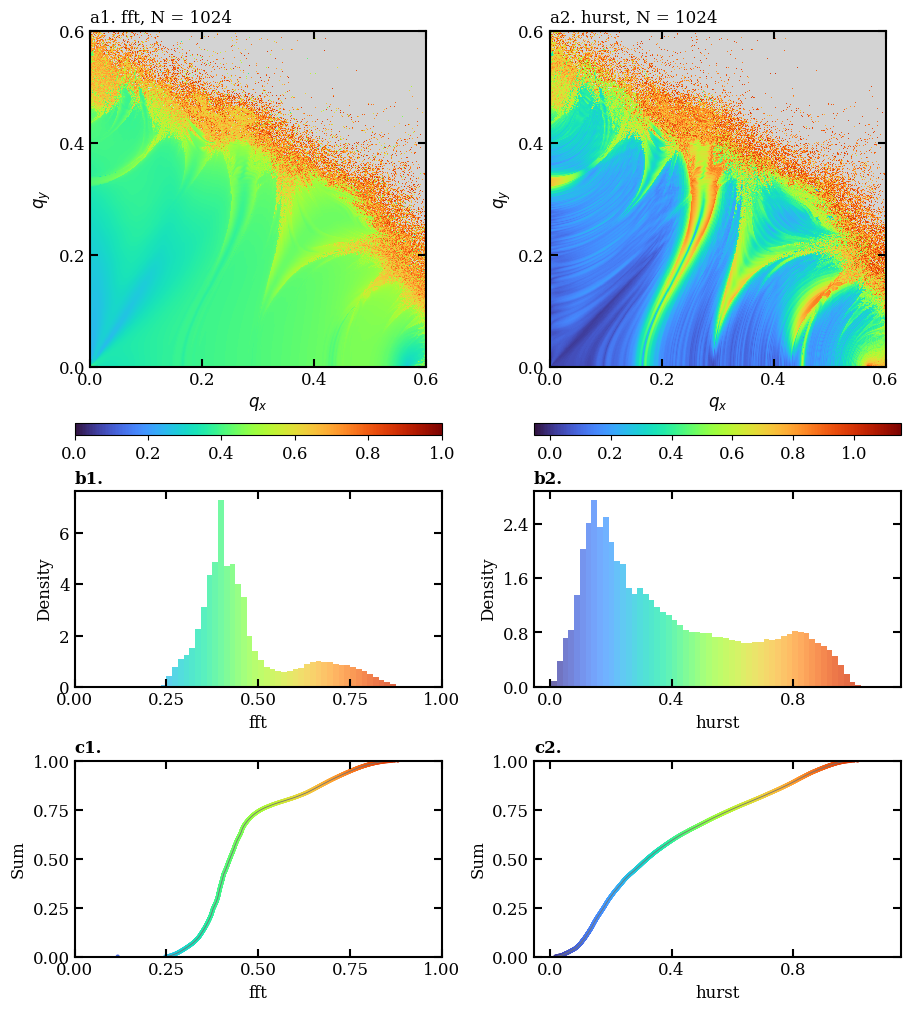

In [9]:
panels(data, [("fft", 1024), ("hurst", 1024)])
plt.show()

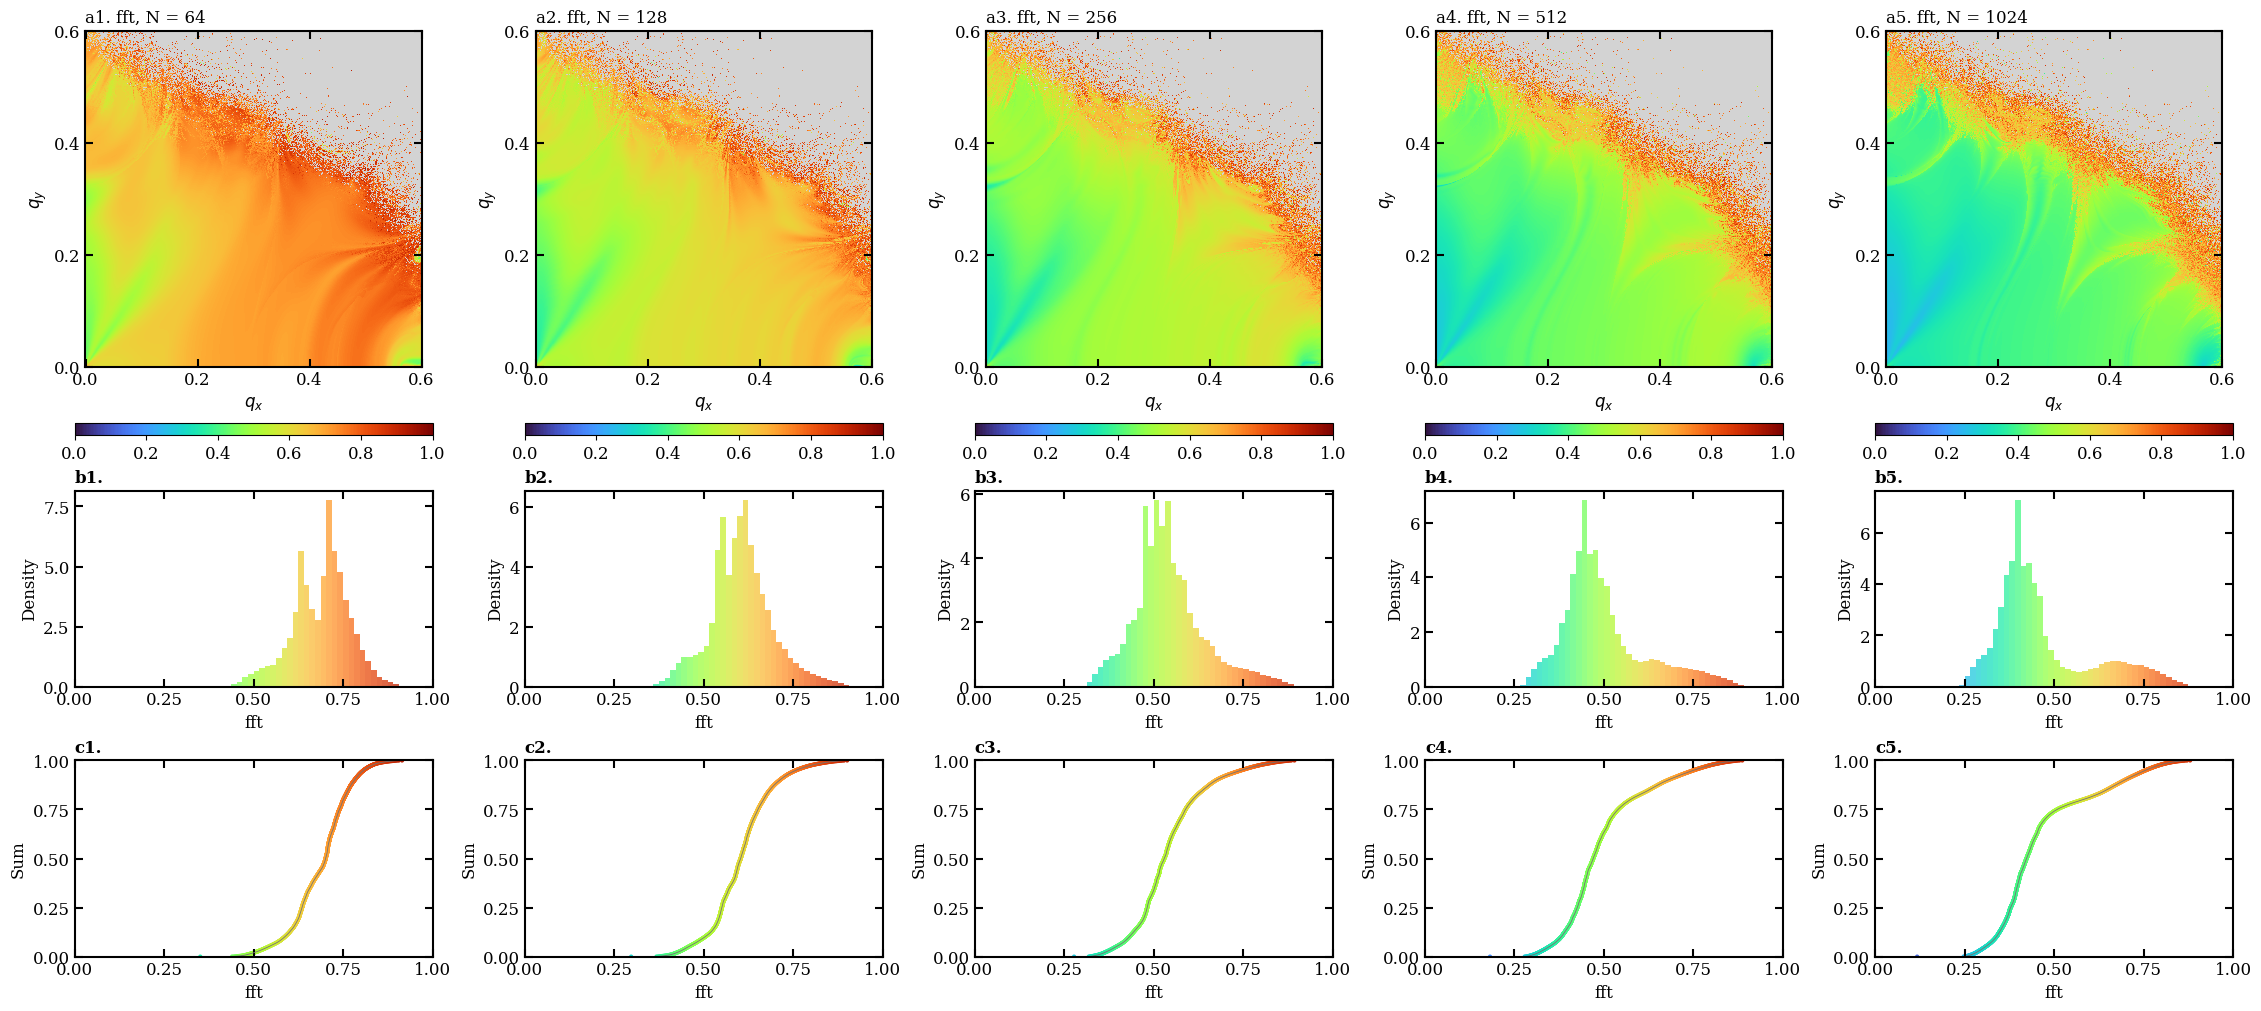

In [10]:
panels(data, [("fft", l) for l in LENGTHS])
plt.show()

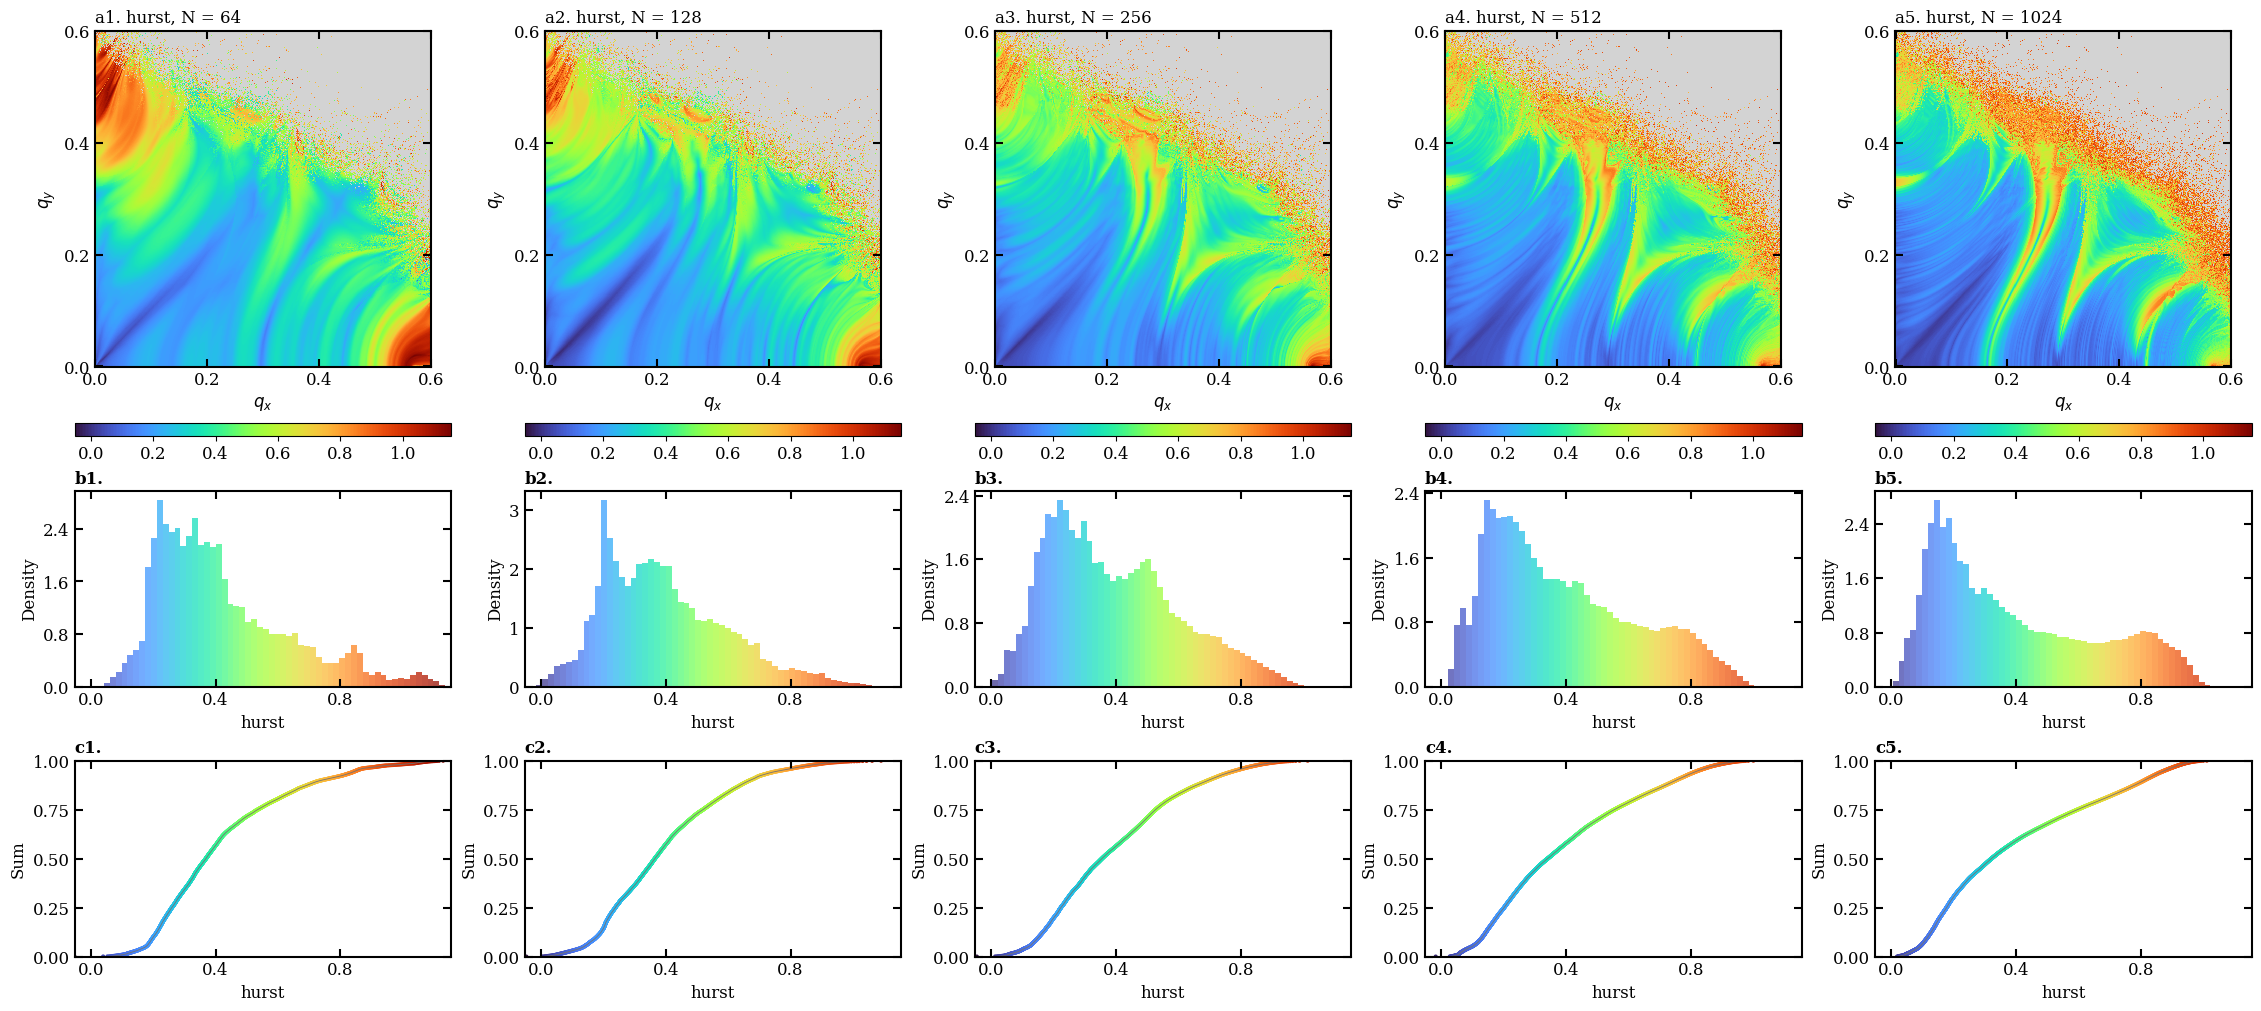

In [11]:
panels(data, [("hurst", l) for l in LENGTHS])
plt.show()

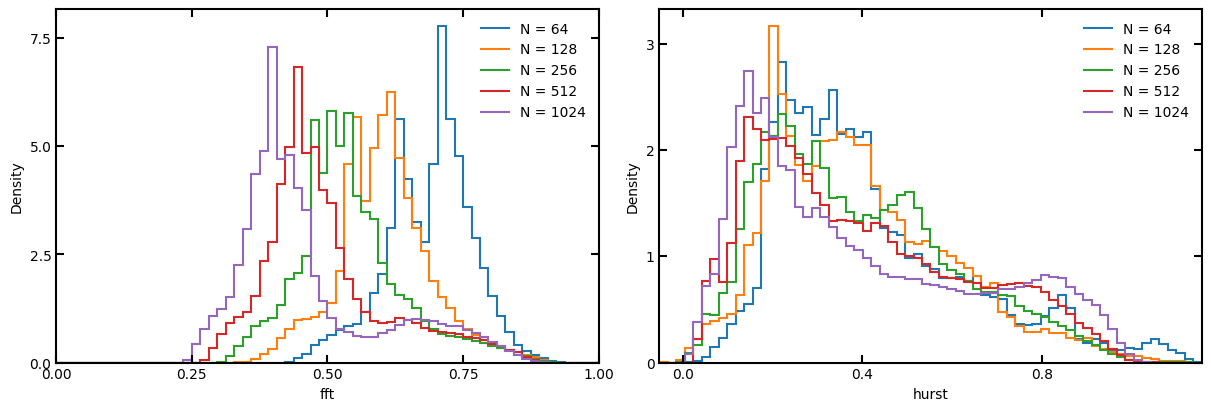

In [12]:
distributions(data)
plt.show()